# Issue #342 — value veto × fixed R3

Executed decision notebook. All tables are loaded from the immutable package.

In [1]:
from pathlib import Path
import json
import pandas as pd
candidates=[Path.cwd(), *Path.cwd().parents]
root=next((p for p in candidates if (p/'results/value_veto_r3_n7').exists()), None)
if root is None: raise FileNotFoundError('results/value_veto_r3_n7 not found')
package=root/'results/value_veto_r3_n7'
decision=json.loads((package/'decision.json').read_text())
decision

{'contract': 'BJ-UNIFIED-VALUE-VETO-R3-N7-001/v2',
 'historical_only': True,
 'issue': 342,
 'modifies_218': False,
 'payout_factor_application': 'ticket_level_once',
 'promotable_to_210': False,
 'r3_robust_under_veto': True,
 'replacement_issues': 0,
 'replacement_rows': 0,
 'verdict': 'NO_INCREMENT',
 'veto_robust_under_r0': False,
 'veto_robust_under_r3': False}

## Data completeness and frozen interval receipt

In [2]:
coverage=pd.read_csv(package/'coverage.csv')
coverage_ledger=pd.read_csv(package/'settlement_coverage_ledger.csv',dtype={'issue':str})
intervals=json.loads((package/'sp_interval_receipt.json').read_text())
display(coverage)
display(coverage_ledger.groupby(['status','reason']).size().rename('issues'))
intervals

,value_surface_rows,value_surface_issues,frozen_issues,settled_common_issues,settled_2023,settled_2024
0,32765,119,119,105,47,58


status    reason              
EXCLUDED  missing_match_label       1
          untrusted_settlement     13
INCLUDED  included                105
Name: issues, dtype: int64

{'calibration_issues': 62,
 'calibration_residual_frame_sha256': '75794d3a2a7ce1c894fd03d30b6b37f389ab90b409dd87460d246a09ddeae752',
 'calibration_year': 2022,
 'calibration_year_used_for_model_selection': False,
 'contract': 'BJ-UNIFIED-VALUE-VETO-R3-N7-001/v2',
 'evaluation_prediction_frame_sha256': 'b663eed396281a252a7dde990701bf128a9f95f80711399903b179860bbbb70b',
 'evaluation_years_unopened': [2023, 2024],
 'final_training_issues': 562,
 'final_training_through_year': 2022,
 'fit_issues': 500,
 'fit_years': [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021],
 'interval_quantiles': [0.1, 0.9],
 'intervals': {'0': {'empirical_coverage': 0.800010559104588,
   'high': 0.1257913963736983,
   'low': -0.1506140755389649,
   'rows': 18941},
  '1': {'empirical_coverage': 0.800010559104588,
   'high': 0.10255017483381534,
   'low': -0.10408141010610161,
   'rows': 18941},
  '3': {'empirical_coverage': 0.800010559104588,
   'high': 0.13534858092369584,
   'low': -0.1206313850421008,
   'rows':

## Absolute capital and matched lift

In [3]:
performance=pd.read_csv(package/'performance.csv')
contrasts=pd.read_csv(package/'contrasts.csv')
display(performance)
display(contrasts)

,cell,issue_year,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_issues,hit_rate,miss_by_1,miss_by_2,mean_replacements
0,S0R0A0,2023,47,48128,34598.374756,-13529.625244,86470.374756,-0.135296,-0.281118,11,0.234043,17,15,0
1,S0R0A0,2024,58,59392,73661.187609,14269.187609,114269.187609,0.142692,0.240254,20,0.344828,18,16,0
2,S0R3A0,2023,47,48128,95942.595888,47814.595888,147814.595888,0.478146,0.993488,9,0.191489,16,12,0
3,S0R3A0,2024,58,59392,140473.373809,81081.373810,181081.373809,0.810814,1.365190,14,0.241379,19,18,0
4,SVR0A0,2023,47,48128,34598.374756,-13529.625244,86470.374756,-0.135296,-0.281118,11,0.234043,17,15,0
5,SVR0A0,2024,58,59392,73661.187609,14269.187609,114269.187609,0.142692,0.240254,20,0.344828,18,16,0
6,SVR3A0,2023,47,48128,95942.595888,47814.595888,147814.595888,0.478146,0.993488,9,0.191489,16,12,0
7,SVR3A0,2024,58,59392,140473.373809,81081.373810,181081.373809,0.810814,1.365190,14,0.241379,19,18,0


,contrast,challenger,control,issue_year,issues,lift_cny,ex_largest_lift_cny,bootstrap_p05_cny,bootstrap_p50_cny,bootstrap_p95_cny,bootstrap_positive_fraction
0,VETO_UNDER_R3,SVR3A0,S0R3A0,2023,47,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
1,VETO_UNDER_R3,SVR3A0,S0R3A0,2024,58,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
2,R3_UNDER_VETO,SVR3A0,SVR0A0,2023,47,61344.221132,405.839021,-16515.805723,56633.225584,182867.841650,0.8285
3,R3_UNDER_VETO,SVR3A0,SVR0A0,2024,58,66812.186200,29497.660626,-19369.383136,64509.962964,170515.078247,0.8930
4,VETO_UNDER_R0,SVR0A0,S0R0A0,2023,47,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
5,VETO_UNDER_R0,SVR0A0,S0R0A0,2024,58,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
6,R3_UNDER_S0,S0R3A0,S0R0A0,2023,47,61344.221132,405.839021,-18188.802590,54979.172246,182150.124059,0.8235
7,R3_UNDER_S0,S0R3A0,S0R0A0,2024,58,66812.186200,29497.660626,-22943.822532,61547.734713,175809.781847,0.8795
8,VETO_R3_INTERACTION,(SVR3A0-S0R3A0),(SVR0A0-S0R0A0),2023,47,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000
9,VETO_R3_INTERACTION,(SVR3A0-S0R3A0),(SVR0A0-S0R0A0),2024,58,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000


## Replacement mechanism and path risk

In [4]:
replacements=pd.read_parquet(package/'replacement_ledger.parquet')
opportunities=pd.read_parquet(package/'veto_opportunity_ledger.parquet')
risk=pd.read_csv(package/'risk_diagnostics.csv')
display(replacements.groupby('issue_year').size().rename('replacement_rows') if len(replacements) else 'No replacements')
display(opportunities.groupby('issue_year').agg(point_positive=('point_margin',lambda x:x.gt(0).sum()), robust_positive=('robust_margin',lambda x:x.gt(0).sum()), best_robust_margin=('robust_margin','max')))
display(risk)

'No replacements'

,point_positive,robust_positive,best_robust_margin
issue_year,,,
2023,342,0,-0.176073
2024,420,0,-0.155114


,cell,issue_year,max_drawdown_fraction,max_consecutive_losing_issues,worst_rolling_5_cny,worst_rolling_10_cny,worst_rolling_20_cny,max_completed_recovery_issues,terminal_underwater_issues,largest_payout_share,payout_hhi
0,S0R0A0,2023,0.259624,12,-5120,-10240.000000,-17626.074799,0,43,0.261810,0.143168
1,S0R0A0,2024,0.116387,7,-5120,-8853.606761,-13180.175749,16,29,0.160739,0.079907
2,S0R3A0,2023,0.131232,21,-5120,-10240.000000,-20064.385379,4,41,0.635155,0.426086
3,S0R3A0,2024,0.197970,10,-5120,-10240.000000,-11491.968309,38,1,0.265634,0.167350
4,SVR0A0,2023,0.259624,12,-5120,-10240.000000,-17626.074799,0,43,0.261810,0.143168
5,SVR0A0,2024,0.116387,7,-5120,-8853.606761,-13180.175749,16,29,0.160739,0.079907
6,SVR3A0,2023,0.131232,21,-5120,-10240.000000,-20064.385379,4,41,0.635155,0.426086
7,SVR3A0,2024,0.197970,10,-5120,-10240.000000,-11491.968309,38,1,0.265634,0.167350


## Capital curves

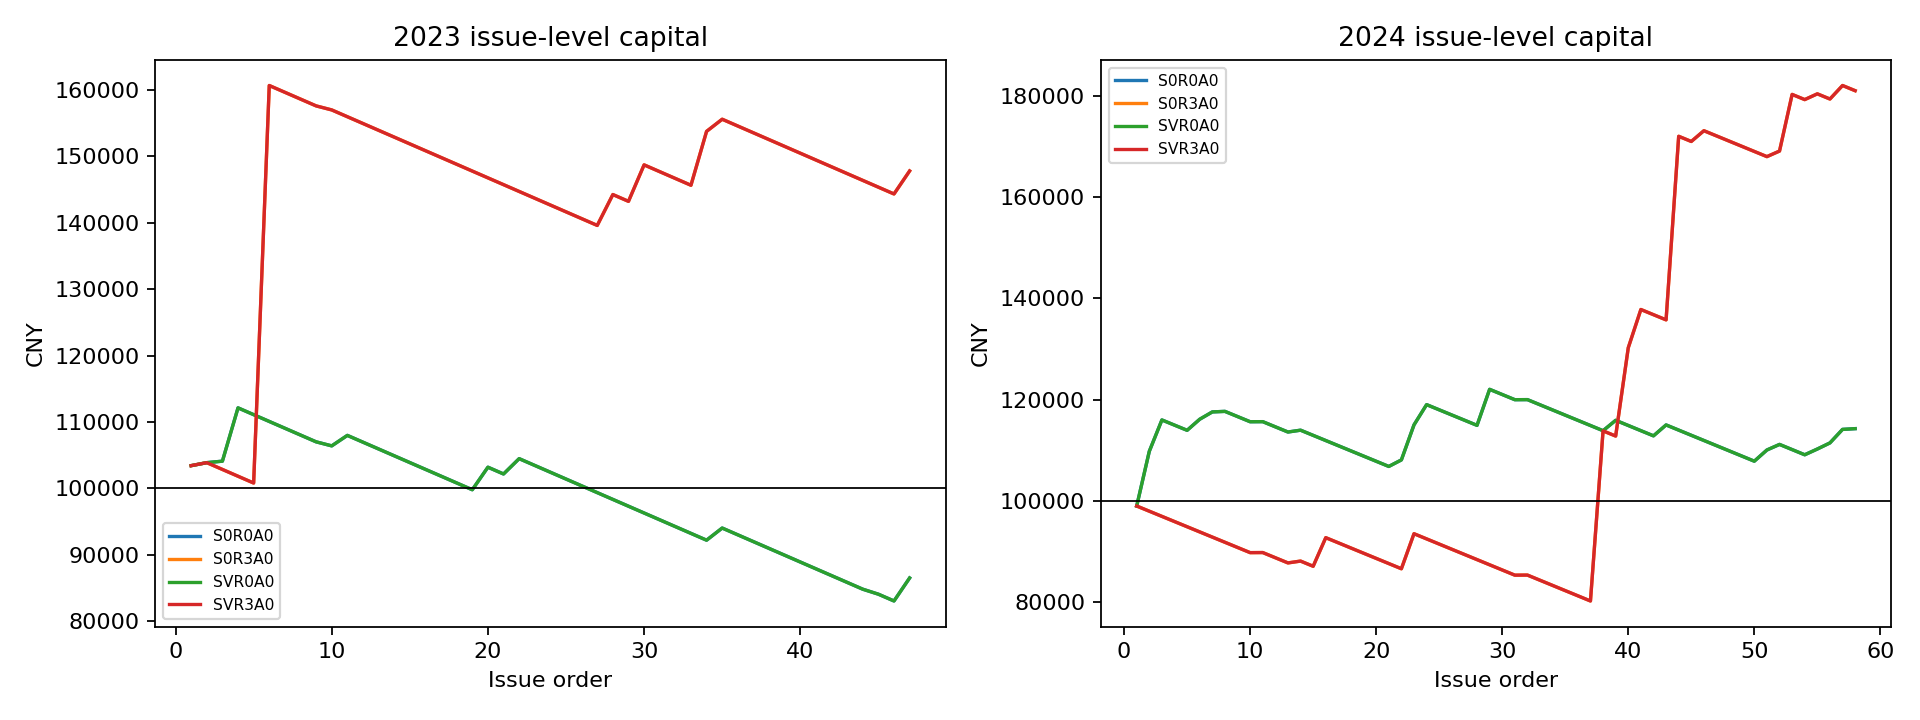

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'docs/research/figures/issue_342_value_veto_capital.png')))

## Decision boundary

This historical result cannot modify #210 or #218. A positive result is a hypothesis for a separate forward contract.